# Dataset Description
## Money spent on pensions over the years by the Central Government

**Source**: [Banco de la República](https://uba.banrep.gov.co/htmlcommons/SeriesHistoricas/sector-publico.html)

# Code
## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

## Load data

In [2]:
path = "./data/banrep_balance_fiscal_gnc_anual_1994_2025.csv"

df = pd.read_csv(
    path, encoding="utf-8", usecols=[0, 52],
    header=0, names=["date", "pensions"]
)

## Clean data

In [3]:
df["date"] = df["date"].str.split("-").str[0].astype(int)
df = df[df["date"] >= 2002]

df["period_start"] = 1994 + ((df["date"] - 1994) // 4) * 4

result = df.groupby("period_start").agg(
    start_year=("date", "min"),
    end_year=("date", "max"),
    start_value=("pensions", "first"),
    end_value=("pensions", "last")
)

result['years_elapsed'] = result['end_year'] - result['start_year']

result['total_growth_%'] = (result['end_value'] / result['start_value'] - 1) * 100

result['annual_growth_%'] = (
    (result['end_value'] / result['start_value']) ** (1 / result['years_elapsed']) - 1
) * 100

result

,start_year,end_year,start_value,end_value,years_elapsed,total_growth_%,annual_growth_%
period_start,,,,,,,
2002,2002,2005,5660.579100,11531.578832,3,103.717299,26.767902
2006,2006,2009,13065.410535,17776.179232,3,36.055267,10.808171
2010,2010,2013,17109.971700,26731.470124,3,56.233281,16.035582
2014,2014,2017,27470.881322,33358.026215,3,21.430492,6.686447
2018,2018,2021,33954.993476,43250.687733,3,27.376516,8.400126
2022,2022,2025,37945.050690,70403.128093,3,85.539686,22.879360


## Plot

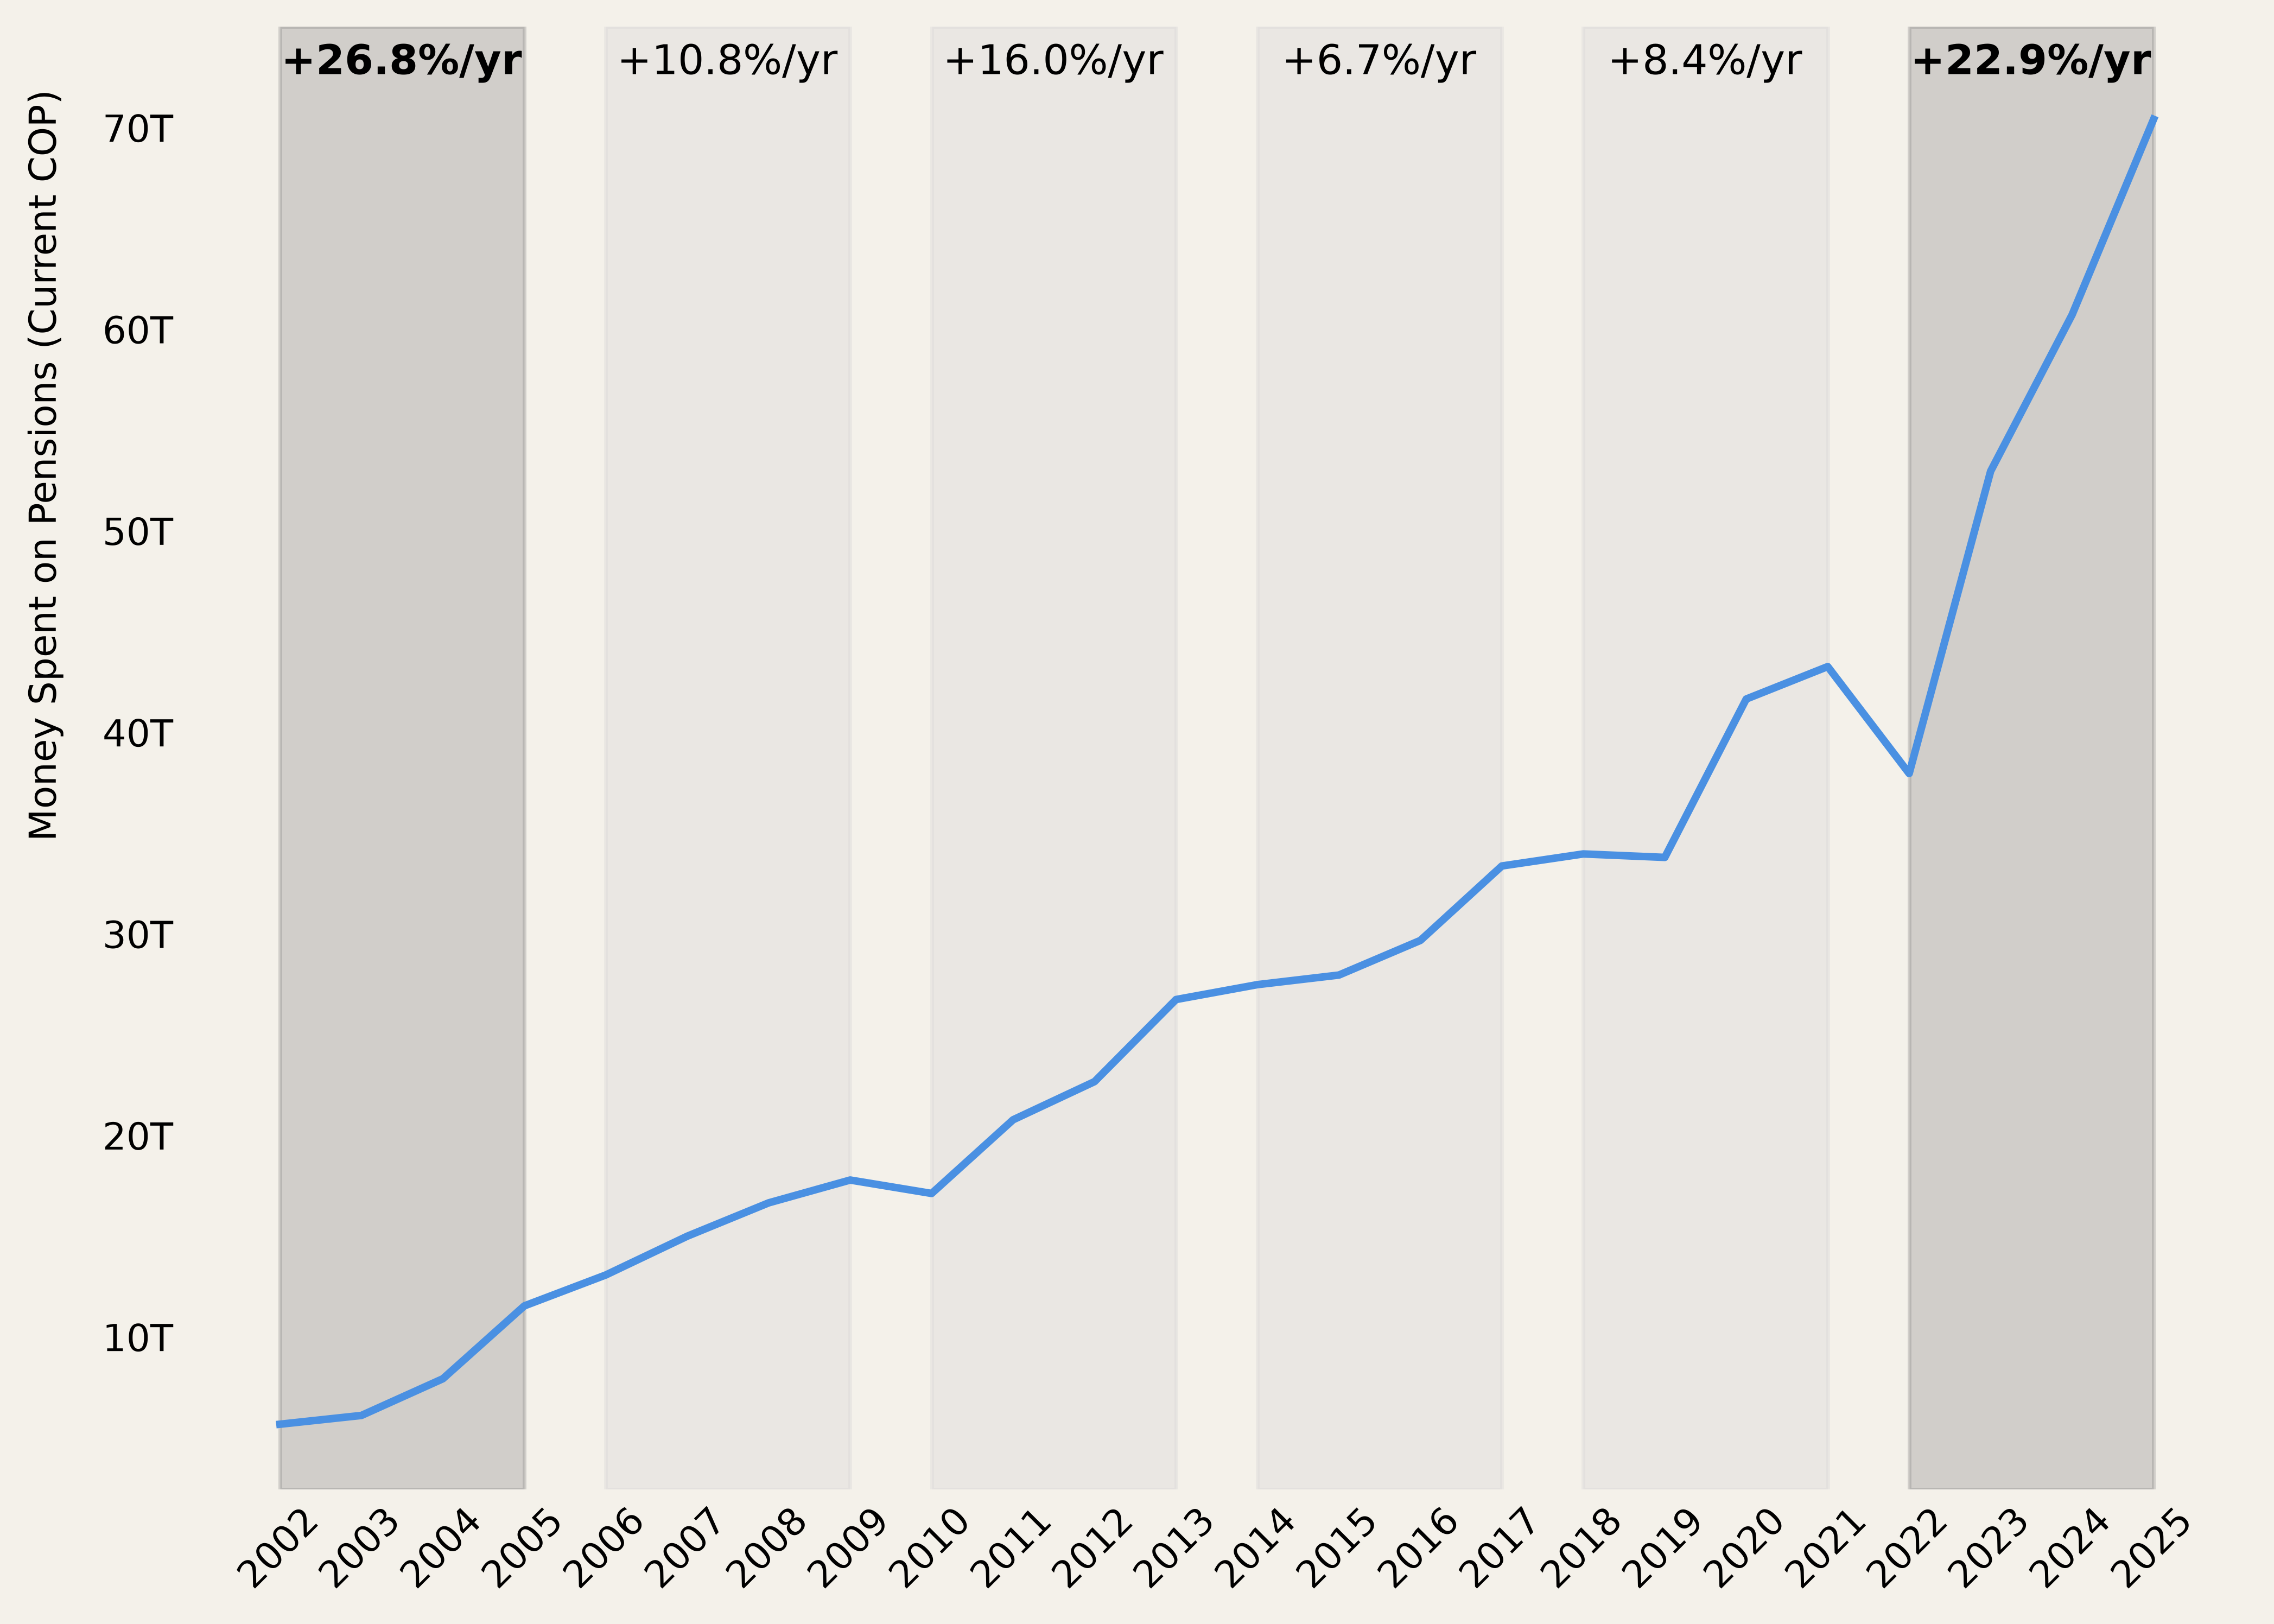

In [36]:
background = "#F4F1EA"
blue = "#4a90e2"
gray = "#D3D3D3"
darker = "#808080"

plt.figure(figsize=(9.8, 7.0), dpi=500, facecolor=background)
plt.gca().set_facecolor(background)

plt.plot(df["date"], df["pensions"], color=blue, linewidth=2)

plt.xticks(df["date"], rotation=45)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.ylim(top=75000)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{int(x/1000)}T" if x != 0 else "0")
)

plt.ylabel("Money Spent on Pensions (Current COP)", labelpad=10, fontsize=10, y=0.7)

for period_start, row in result.iterrows():
    huge = row["annual_growth_%"] > 20

    plt.axvspan(
        xmin=period_start, xmax=row.end_year, 
        color=darker if huge else gray,
        alpha=0.3
    )

    x = row.end_year - 1 
    y = result["end_value"].max()

    plt.annotate(
        f"+{row["annual_growth_%"]:.1f}%/yr",
        xy=(x,y),
        xytext=(-11,12),
        textcoords="offset points",
        fontsize=11,
        ha="center",
        fontweight="bold" if huge else "normal"
    )

plt.show()